# 06 Cross event generalisation

**Notebook 6 of 6, xBD building damage assessment**

Train, test and the holdout split of xBD all contain the same ten Tier1 events,
so even the holdout evaluation in notebook 5 shows events the models have seen
during training, only on different images. Images of one event are often very
similar, which makes that estimate optimistic for a new disaster.

This notebook removes three events from the training data completely and
evaluates on exactly those events:

| | |
|---|---|
| held out | hurricane-michael, santa-rosa-wildfire, palu-tsunami |
| why these | wind, fire and tsunami damage, three different damage patterns |
| model | Siamese ResNet50, the best single model of notebook 4 |
| evaluation | full holdout images, every model with its own building mask |

Removing events also removes training images, which on its own could lower the
result. The evaluation therefore covers two groups of holdout images: the three
held out events, and a sample of the remaining seven. Comparing both models on
both groups separates the two effects.

UNet1 is not used here. It was trained on all events, so a score that takes its
localisation would carry knowledge of the held out events. Instead every model
provides its own building mask, which is simply everything it predicts as class
1 or higher. That gives the same three numbers as in notebook 5, localisation
F1, damage F1 and the combined score, without any leakage, and it also shows
whether building detection itself suffers on unknown events.

Requires `01_data_check.ipynb`, the checkpoint of notebook 4 and the holdout split.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
from PIL import Image
import matplotlib.pyplot as pl
import torch
from torch.utils.data import DataLoader

import config
from common import data, crops, models, losses, train, evaluate, plots

pl.rcParams["figure.dpi"] = 120
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

paths = data.resolve_splits(config.DATA_ROOT)
file_lists = {split: data.list_pre_images(paths[split]["images"]) for split in paths}
print("data root:", config.DATA_ROOT)
for split in config.SPLIT_FOLDERS:
    if split not in paths:
        print(f"{split}: not found, skipped")
for split, files in file_lists.items():
    print(f"{split}: {len(files)} pre-disaster images")


/DATA/schrepel/ml_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
data root: /DATA/schrepel/xbd_new/data
train: 2746 pre-disaster images
test: 917 pre-disaster images
hold: 933 pre-disaster images
tier3: 6288 pre-disaster images


In [2]:
# Holdout images of the remaining events, as a control group. None means all of them.
N_CONTROL_IMAGES = 200

## 1. Data without the held out events

The building filter and the crop rules are the same as in notebooks 3 and 4,
only the event lists differ. Training uses train and tier3 without the three
events, validation uses the test split without them as well, so the checkpoint
is selected without ever seeing them.

In [3]:
all_building_files = []
for split in ("train", "tier3", "test"):
    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png")))
        if (target > 0).mean() >= config.MIN_BUILDING_FRACTION:
            all_building_files.append((split, stem))

train_files = [(s, stem) for s, stem in all_building_files
               if s in ("train", "tier3") and data.event_of(stem) not in config.HELD_OUT_EVENTS]
val_files = [(s, stem) for s, stem in all_building_files
             if s == "test" and data.event_of(stem) not in config.HELD_OUT_EVENTS]
dropped = [(s, stem) for s, stem in all_building_files
           if s in ("train", "tier3") and data.event_of(stem) in config.HELD_OUT_EVENTS]

print(f"{len(train_files)} training images, {len(dropped)} dropped with the held out events")
print(f"{len(val_files)} validation images, all from events the model also trains on")

4198 training images, 638 dropped with the held out events
483 validation images, all from events the model also trains on


In [4]:
EVENT_HOLDOUT_TILES = "val_damage_raw_tiles_event_holdout.pt"

if not (config.VAL_TILES_DIR / EVENT_HOLDOUT_TILES).exists():
    tiles = crops.draw_raw_tiles(val_files, paths, config.N_VAL_CROPS)
    torch.save(tiles, config.VAL_TILES_DIR / EVENT_HOLDOUT_TILES)
    print(f"saved {len(tiles)} tiles to {config.VAL_TILES_DIR / EVENT_HOLDOUT_TILES}")

In [5]:
val_tiles_event_holdout = train.load_val_tiles(EVENT_HOLDOUT_TILES)
crops.describe_tiles(val_tiles_event_holdout, "test split without the held out events")

loaded /DATA/schrepel/xbd_new/val_tiles/val_damage_raw_tiles_event_holdout.pt (5796 tiles)


test split without the held out events: 5796 tiles, 77.0% positive, 2.63% damaged building pixels


## 2. Model, dataset and training loop

In [6]:
val_loader_event_holdout = DataLoader(
    crops.FixedSiameseDataset(val_tiles_event_holdout, crops.damage_identity, normalize=True),
    batch_size=config.BATCH_SIZE, shuffle=False)

## 3. Training without the three events

Same setup as the Siamese ResNet50 in notebook 4: damage aware sampling,
rotations, scale and colour augmentation, ImageNet normalization, encoder at a
fifth of the learning rate and cosine decay. Only the training and validation
files differ.

In [7]:
if not (config.CKPT_DIR / "damage_siamese_resnet_event_holdout.pt").exists():
    train_loader_event_holdout = DataLoader(
        crops.SiameseDamageDataset(train_files, paths, crops.damage_identity, n_crops=12, augment=True,
                             damage_probability=0.5, normalize=True,
                             scale_range=(0.8, 1.25), rotate=True, color_jitter=True),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)

    torch.manual_seed(357)
    model_event_holdout = models.SiameseResNetUNet(out_channels=5, encoder_name="resnet50",
                                            encoder_weights="imagenet").to(device)

    train.train_model(model_event_holdout, train_loader_event_holdout, [val_loader_event_holdout],
                config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "damage_siamese_resnet_event_holdout.pt",
                config.HISTORY_DIR / "history_siamese_resnet_event_holdout.pt",
                loss_fn=losses.WeightedMultiClassDiceLoss(n_classes=5, device=device),
                siamese=True,
                slow_prefixes=("encoder",), slow_lr_factor=0.2,
                cosine=True)

In [8]:
# encoder_weights=None: the ImageNet weights are overwritten by the checkpoint anyway
model_event_holdout = models.SiameseResNetUNet(out_channels=5, encoder_name="resnet50",
                                        encoder_weights=None).to(device)
train.load_checkpoint(model_event_holdout, "damage_siamese_resnet_event_holdout.pt", device)

model_all_events = models.SiameseResNetUNet(out_channels=5, encoder_name="resnet50",
                                     encoder_weights=None).to(device)
train.load_checkpoint(model_all_events, "damage_siamese_resnet_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/damage_siamese_resnet_event_holdout.pt


loaded /DATA/schrepel/xbd_new/checkpoints/damage_siamese_resnet_best.pt


SiameseResNetUNet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Seque

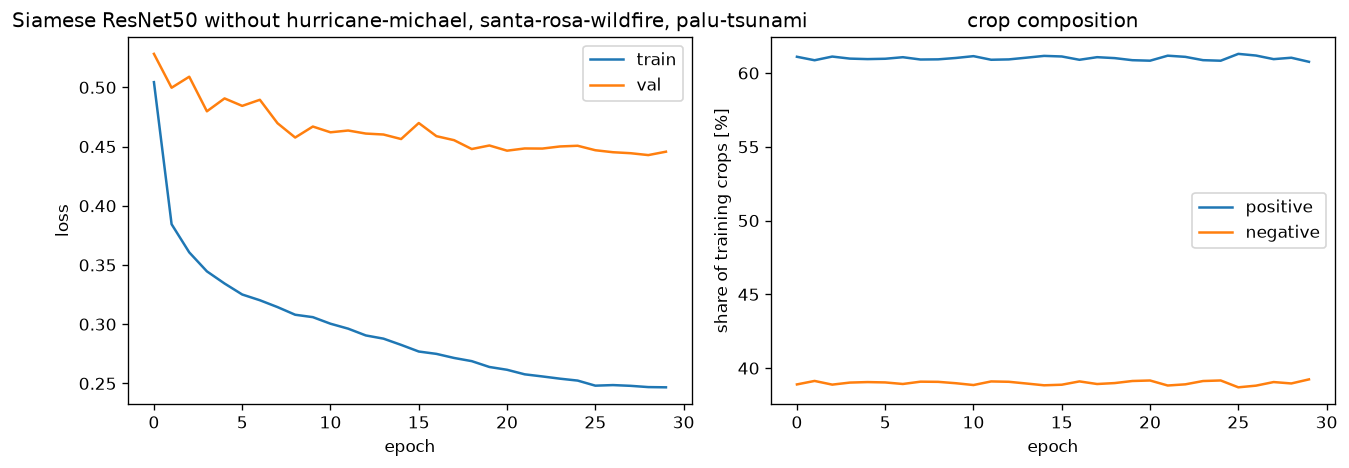

In [9]:
plots.plot_history(train.load_history("history_siamese_resnet_event_holdout.pt"),
             "Siamese ResNet50 without hurricane-michael, santa-rosa-wildfire, palu-tsunami")

## 4. Evaluation on full holdout images

Both models run over the same images with the same sliding window as in notebook
5. Each model supplies its own building mask (class 1 or higher) for the
localisation part, and damage is counted on the pixels that are buildings in the
ground truth, as in the official scoring. The control group is a random sample
of the holdout images of the seven events that both models trained on.

In [10]:
hold_stems = [f.replace("_pre_disaster.png", "") for f in file_lists["hold"]]
control_pool = [s for s in hold_stems if data.event_of(s) not in config.HELD_OUT_EVENTS]

np.random.seed(357)
control_stems = sorted(np.random.choice(
    control_pool, min(N_CONTROL_IMAGES or len(control_pool), len(control_pool)), replace=False))

# one group per held out event, plus the control group of the remaining events
groups = {event: [s for s in hold_stems if data.event_of(s) == event] for event in config.HELD_OUT_EVENTS}
groups["other events"] = list(control_stems)

for group, stems in groups.items():
    print(f"{group:<22s}{len(stems):>5d} holdout images")
print(f"\ncontrol images drawn from {len(control_pool)} images of "
      f"{len(set(data.event_of(s) for s in control_pool))} events")

hurricane-michael       109 holdout images
santa-rosa-wildfire      77 holdout images
palu-tsunami             41 holdout images
other events            200 holdout images

control images drawn from 706 images of 7 events


In [11]:
def predict_damage(model, pre_image, post_image, n_classes=5, device="cpu", batch_size=8):
    """Sliding window damage prediction of one Siamese model, averaged over the overlaps."""
    pre_t, post_t = crops.to_chw(pre_image, normalize=True), crops.to_chw(post_image, normalize=True)
    _, height, width = pre_t.shape

    prob_map = torch.zeros(n_classes, height, width)
    count_map = torch.zeros(height, width)

    model.eval()
    positions = evaluate.tile_positions(height, width)
    with torch.no_grad():
        for i in range(0, len(positions), batch_size):
            chunk = positions[i:i + batch_size]
            pre_batch = torch.stack([pre_t[:, r:r + config.TILE_SIZE, c:c + config.TILE_SIZE]
                                     for r, c in chunk]).to(device)
            post_batch = torch.stack([post_t[:, r:r + config.TILE_SIZE, c:c + config.TILE_SIZE]
                                      for r, c in chunk]).to(device)
            probs = torch.softmax(model(pre_batch, post_batch), dim=1).cpu()

            for (r, c), p in zip(chunk, probs):
                prob_map[:, r:r + config.TILE_SIZE, c:c + config.TILE_SIZE] += p
                count_map[r:r + config.TILE_SIZE, c:c + config.TILE_SIZE] += 1

    count_map[count_map == 0] = 1
    return (prob_map / count_map.unsqueeze(0)).argmax(0).numpy().astype(np.uint8)

In [12]:
def evaluate_groups(models, groups, device, report_every=25):
    """Localisation and damage counts per model and group, plus the label distribution.

    Localisation: everything a model predicts as class 1 or higher against the
    pre-disaster target. Damage: the four damage classes on the pixels that are
    buildings in the post-disaster target, as in the official scoring.
    gt_pixels: how many ground truth pixels of each class a group contains.
    """
    localisation = {(m, g): evaluate.ConfusionCounter(2) for m in models for g in groups}
    damage = {(m, g): evaluate.ConfusionCounter(5) for m in models for g in groups}
    gt_pixels = {g: np.zeros(5, dtype=np.int64) for g in groups}
    image_dir, target_dir = paths["hold"]["images"], paths["hold"]["targets"]

    for group, stems in groups.items():
        for i, stem in enumerate(stems, start=1):
            pre_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_pre_disaster.png")))
            post_image = np.array(Image.open(os.path.join(image_dir, f"{stem}_post_disaster.png")))
            pre_target = np.array(Image.open(
                os.path.join(target_dir, f"{stem}_pre_disaster_target.png")))
            post_target = np.array(Image.open(
                os.path.join(target_dir, f"{stem}_post_disaster_target.png")))

            buildings = (pre_target > 0).astype(np.uint8)
            on_buildings = post_target > 0
            gt_pixels[group] += np.bincount(post_target.ravel(), minlength=5)[:5]

            for name, model in models.items():
                prediction = predict_damage(model, pre_image, post_image, device=device)
                localisation[(name, group)].update((prediction >= 1).astype(np.uint8), buildings)
                damage[(name, group)].update(prediction[on_buildings], post_target[on_buildings])

            if i % report_every == 0 or i == len(stems):
                print(f"{group}: {i}/{len(stems)} images")

    return localisation, damage, gt_pixels


trained_models = {"without the events": model_event_holdout, "with the events": model_all_events}

done = config.RESULTS_DIR / "cross_event_evaluation.json"
if done.exists():
    saved = evaluate.load_counters(done)
    localisation = {(m, g): c for m, per_group in saved["localisation"].items()
                    for g, c in per_group.items()}
    damage = {(m, g): c for m, per_group in saved["damage"].items()
              for g, c in per_group.items()}
    gt_pixels = saved["gt_pixels"]
    print(f"loaded {done}")
else:
    localisation, damage, gt_pixels = evaluate_groups(trained_models, groups, device)
    evaluate.save_counters(done, {
        "localisation": {m: {g: localisation[(m, g)] for g in groups}
                         for m in trained_models},
        "damage": {m: {g: damage[(m, g)] for g in groups} for m in trained_models},
        "gt_pixels": gt_pixels})

hurricane-michael: 25/109 images


hurricane-michael: 50/109 images


hurricane-michael: 75/109 images


hurricane-michael: 100/109 images


hurricane-michael: 109/109 images


...

other events: 100/200 images


other events: 125/200 images


other events: 150/200 images


other events: 175/200 images


other events: 200/200 images


In [13]:
def harmonic_mean_eps(f1s):
    """Harmonic mean with the epsilon of the official scoring script."""
    return len(f1s) / sum(1 / (f1 + 1e-6) for f1 in f1s)


def damage_f1(counter):
    """F1 per damage class and their harmonic mean."""
    per_class = counter.per_class()
    return per_class, harmonic_mean_eps([per_class[c][2] for c in config.DAMAGE_CLASSES])


def add_counters(counters):
    """Counters are additive, so groups can be pooled after the fact."""
    total = evaluate.ConfusionCounter(counters[0].n_classes)
    for counter in counters:
        total.tp = total.tp + counter.tp
        total.fp = total.fp + counter.fp
        total.fn = total.fn + counter.fn
    return total


# the three held out events pooled into one row
held_out_groups = [g for g in groups if g != "other events"]
for name in trained_models:
    localisation[(name, "held out events")] = add_counters(
        [localisation[(name, g)] for g in held_out_groups])
    damage[(name, "held out events")] = add_counters([damage[(name, g)] for g in held_out_groups])
gt_pixels["held out events"] = sum(gt_pixels[g] for g in held_out_groups)

report_groups = held_out_groups + ["held out events", "other events"]

In [14]:
header = (f"{'images':<22s}{'model':<22s}"
          + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in config.DAMAGE_CLASSES)
          + f"{'F1 damage':>12s}{'F1 loc':>9s}{'score':>9s}")
print(header)
for group in report_groups:
    for name in trained_models:
        per_class, f1_damage = damage_f1(damage[(name, group)])
        f1_loc = localisation[(name, group)].per_class()[1][2]
        f1s = "".join(f"{per_class[c][2]:>12.3f}" for c in config.DAMAGE_CLASSES)
        print(f"{group:<22s}{name:<22s}{f1s}{f1_damage:>12.3f}{f1_loc:>9.3f}"
              f"{0.3 * f1_loc + 0.7 * f1_damage:>9.3f}")
    print()

images                model                    no-damage       minor       major   destroyed   F1 damage   F1 loc    score
hurricane-michael     without the events           0.733       0.421       0.323       0.417       0.433    0.842    0.556
hurricane-michael     with the events              0.716       0.504       0.514       0.454       0.531    0.849    0.627

santa-rosa-wildfire   without the events           0.779       0.004       0.062       0.853       0.016    0.847    0.265
santa-rosa-wildfire   with the events              0.910       0.022       0.186       0.919       0.076    0.872    0.315

palu-tsunami          without the events           0.770       0.000       0.169       0.566       0.000    0.846    0.254
palu-tsunami          with the events              0.917       0.000       0.359       0.773       0.000    0.888    0.266

held out events       without the events           0.759       0.297       0.267       0.764       0.410    0.845    0.541
held out even

### What the evaluated images contain

Class shares of the ground truth, counted over exactly the images that were
evaluated. F1 values of a class may only be compared between the two models
inside one group, never between groups, because the groups hold very different
amounts of each class. The absolute pixel counts show which value rests on
enough data.

In [15]:
print(f"{'images':<22s}{'building pixels':>17s}"
      + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in config.DAMAGE_CLASSES))
for group in report_groups:
    counts = gt_pixels[group]
    buildings = counts[1:].sum()
    shares = "".join(f"{100 * counts[c] / buildings:>11.1f}%" for c in config.DAMAGE_CLASSES)
    print(f"{group:<22s}{buildings / 1e6:>14.2f} M{shares}")

print(f"\nabsolute ground truth pixels per class")
print(f"{'images':<22s}" + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in config.DAMAGE_CLASSES))
for group in report_groups:
    counts = gt_pixels[group]
    print(f"{group:<22s}" + "".join(f"{counts[c] / 1e6:>10.2f} M" for c in config.DAMAGE_CLASSES))

images                  building pixels   no-damage       minor       major   destroyed
hurricane-michael               9.16 M       59.0%       24.4%       13.6%        2.9%
santa-rosa-wildfire             5.76 M       67.7%        0.5%        0.5%       31.2%
palu-tsunami                    7.80 M       89.4%        0.0%        3.8%        6.8%
held out events                22.71 M       71.7%       10.0%        6.9%       11.4%
other events                   12.33 M       76.5%       10.5%       11.7%        1.3%

absolute ground truth pixels per class
images                   no-damage       minor       major   destroyed
hurricane-michael           5.41 M      2.23 M      1.25 M      0.27 M
santa-rosa-wildfire         3.90 M      0.03 M      0.03 M      1.80 M
palu-tsunami                6.97 M      0.00 M      0.30 M      0.53 M
held out events            16.28 M      2.26 M      1.58 M      2.60 M
other events                9.44 M      1.29 M      1.45 M      0.16 M


### Where the drop comes from

The first table gives the difference between the two models per class. The second
one isolates the classes: it takes the per class F1 values of the model trained
without the events, replaces one class at a time by the value of the other model
and recomputes the harmonic mean. The gain shows how much of the gap that single
class explains. The harmonic mean is not additive, so the shares do not add up to
exactly 100 percent.

In [16]:
print("difference, model without the events minus model with the events")
print(f"{'images':<22s}" + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in config.DAMAGE_CLASSES)
      + f"{'F1 damage':>12s}{'F1 loc':>9s}{'score':>9s}")

for group in report_groups:
    without, f1_without = damage_f1(damage[("without the events", group)])
    with_, f1_with = damage_f1(damage[("with the events", group)])
    loc_without = localisation[("without the events", group)].per_class()[1][2]
    loc_with = localisation[("with the events", group)].per_class()[1][2]

    score_without = 0.3 * loc_without + 0.7 * f1_without
    score_with = 0.3 * loc_with + 0.7 * f1_with
    deltas = "".join(f"{without[c][2] - with_[c][2]:>+12.3f}" for c in config.DAMAGE_CLASSES)
    print(f"{group:<22s}{deltas}{f1_without - f1_with:>+12.3f}{loc_without - loc_with:>+9.3f}"
          f"{score_without - score_with:>+9.3f}")

difference, model without the events minus model with the events
images                   no-damage       minor       major   destroyed   F1 damage   F1 loc    score
hurricane-michael           +0.017      -0.083      -0.191      -0.037      -0.098   -0.006   -0.071
santa-rosa-wildfire         -0.130      -0.018      -0.124      -0.067      -0.061   -0.025   -0.050
palu-tsunami                -0.147      +0.000      -0.190      -0.207      -0.000   -0.042   -0.012
held out events             -0.095      -0.200      -0.217      -0.089      -0.212   -0.023   -0.156
other events                -0.007      -0.039      -0.001      -0.010      -0.020   -0.004   -0.015


In [17]:
for group in report_groups:
    without, f1_without = damage_f1(damage[("without the events", group)])
    with_, f1_with = damage_f1(damage[("with the events", group)])
    gap = f1_with - f1_without

    if gap <= 0.001:
        print(f"{group}: no gap to explain, F1 damage {f1_without:.3f} against {f1_with:.3f}\n")
        continue

    print(f"{group}: F1 damage {f1_without:.3f} against {f1_with:.3f}, gap {gap:.3f}")
    print(f"  {'class set to the other model':<32s}{'F1 damage':>12s}{'gain':>9s}{'of the gap':>13s}")
    for c in config.DAMAGE_CLASSES:
        patched = [with_[k][2] if k == c else without[k][2] for k in config.DAMAGE_CLASSES]
        value = harmonic_mean_eps(patched)
        print(f"  {config.FIVE_CLASS_NAMES[c]:<32s}{value:>12.3f}{value - f1_without:>+9.3f}"
              f"{100 * (value - f1_without) / gap:>12.0f}%")
    print()

hurricane-michael: F1 damage 0.433 against 0.531, gap 0.098
  class set to the other model       F1 damage     gain   of the gap
  no-damage                              0.432   -0.001          -2%
  minor                                  0.452   +0.019          19%
  major                                  0.495   +0.062          63%
  destroyed                              0.442   +0.009          10%

santa-rosa-wildfire: F1 damage 0.016 against 0.076, gap 0.061
  class set to the other model       F1 damage     gain   of the gap
  no-damage                              0.016   +0.000           0%
  minor                                  0.063   +0.047          78%
  major                                  0.016   +0.001           1%
  destroyed                              0.016   +0.000           0%

palu-tsunami: no gap to explain, F1 damage 0.000 against 0.000

held out events: F1 damage 0.410 against 0.623, gap 0.212
  class set to the other model       F1 damage     gain   of the

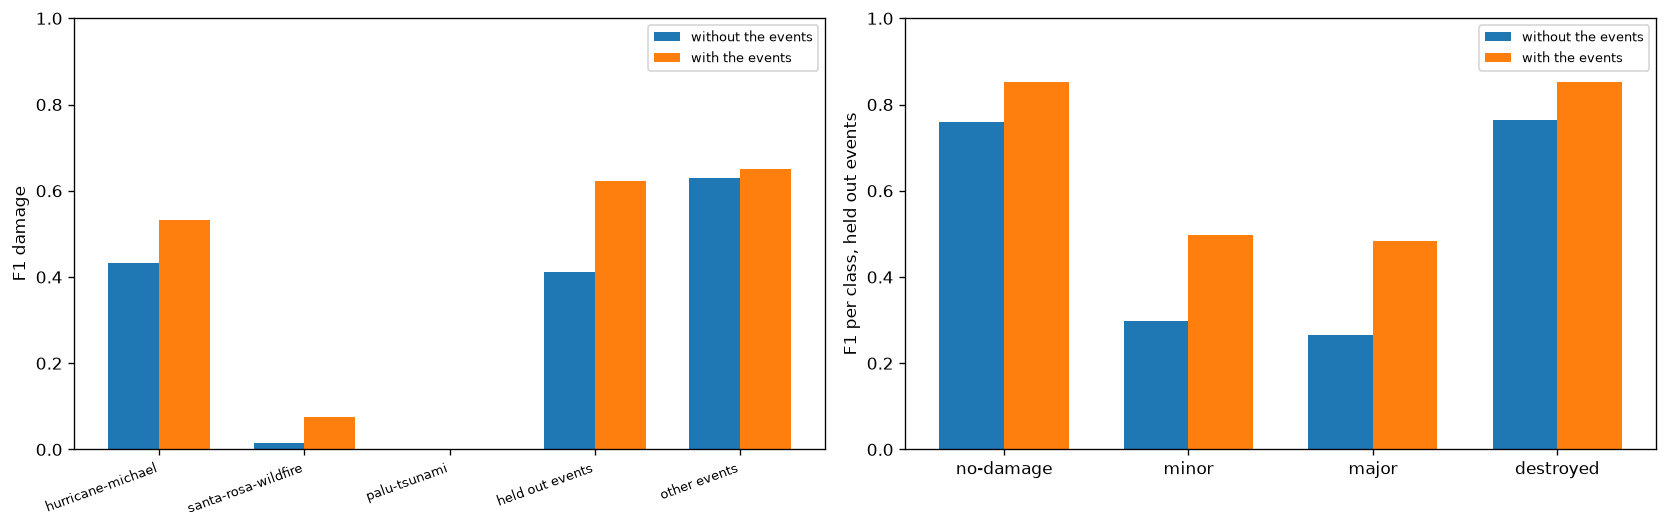

In [18]:
fig, ax = pl.subplots(1, 2, figsize=(14, 4.5))

positions = np.arange(len(report_groups))
width = 0.35
for i, name in enumerate(trained_models):
    values = [damage_f1(damage[(name, g)])[1] for g in report_groups]
    ax[0].bar(positions + (i - 0.5) * width, values, width, label=name, color=f"C{i}")
ax[0].set_xticks(positions)
ax[0].set_xticklabels(report_groups, rotation=20, ha="right", fontsize=8)
ax[0].set_ylabel("F1 damage")
ax[0].set_ylim(0, 1)
ax[0].legend(fontsize=8)

positions = np.arange(len(config.DAMAGE_CLASSES))
for i, name in enumerate(trained_models):
    per_class, _ = damage_f1(damage[(name, "held out events")])
    ax[1].bar(positions + (i - 0.5) * width, [per_class[c][2] for c in config.DAMAGE_CLASSES], width,
              label=name, color=f"C{i}")
ax[1].set_xticks(positions)
ax[1].set_xticklabels([config.FIVE_CLASS_NAMES[c] for c in config.DAMAGE_CLASSES])
ax[1].set_ylabel("F1 per class, held out events")
ax[1].set_ylim(0, 1)
ax[1].legend(fontsize=8)

pl.tight_layout()
pl.show()

How to read the tables: inside one group both models run over the same scenes,
so they differ only in their training data. The rows of the three held out events
are the actual test, the row "other events" is the control, where both models
know the event type and differ only by the 13 percent of training images that
were removed. A clear gap on the held out events next to a small gap on the
control group means the drop comes from the unknown event types and not from the
smaller training set.

For santa-rosa-wildfire and palu-tsunami the classes minor and major hold very
few pixels, so their F1 values there are noisy. The pixel table above shows how
much data each value rests on.

The score uses the weighting of notebook 5, but its localisation part comes from
the damage model itself rather than from UNet1, so the numbers are not directly
comparable to table 3 there.